In [62]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# issse phele walo me train and test already splited the isme karna padega  islia sklearn chaiye 

In [63]:
data = pd.read_csv('ecg.csv' , header=None)

In [64]:
data.head

<bound method NDFrame.head of            0         1         2         3         4         5         6    \
0    -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1    -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2    -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3     0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4     0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   
...        ...       ...       ...       ...       ...       ...       ...   
4993  0.608558 -0.335651 -0.990948 -1.784153 -2.626145 -2.957065 -2.931897   
4994 -2.060402 -2.860116 -3.405074 -3.748719 -3.513561 -3.006545 -2.234850   
4995 -1.122969 -2.252925 -2.867628 -3.358605 -3.167849 -2.638360 -1.664162   
4996 -0.547705 -1.889545 -2.839779 -3.457912 -3.929149 -3.966026 -3.492560   
4997 -1.351779 -2.209006 -2.520225 -3.061475 -3.065141 -3.030739 -2.622720   

           7         8         9 

In [65]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

# .values to convert it to numpy array 

In [66]:
x_train , x_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state=42)

In [67]:
x_train

array([[ 0.78629121, -0.91905142, -2.5799097 , ...,  1.4646253 ,
         1.3666739 , -0.31022852],
       [ 0.49877281, -0.22197073, -0.69678617, ..., -0.11301007,
        -0.35893115,  0.27107582],
       [-1.292827  , -2.7944135 , -3.0510357 , ...,  0.34328906,
         0.69494799,  0.08580568],
       ...,
       [-1.0320965 , -2.8119009 , -3.5887058 , ...,  1.5680471 ,
         1.7765205 ,  0.75066935],
       [-1.5925409 , -2.4613697 , -2.5241322 , ..., -1.0776759 ,
        -0.70754117,  0.35401601],
       [-1.9455858 , -3.8405188 , -3.9946828 , ...,  0.95197929,
         0.88314532, -1.3660438 ]], shape=(3998, 140))

In [68]:
low = x_train.min() 
high = x_train.max()

# standardise 
x_train = (x_train - low) / (high - low)
x_test = (x_test - low) / (high - low)

In [69]:
print(x_train.max())

1.0


In [70]:
print(x_train.min())

0.0


In [71]:
x_train_normal = x_train[y_train == 1]

In [72]:
print("Normal training samples:", x_train_normal.shape)

Normal training samples: (2328, 140)


In [73]:
encoder = keras.Sequential([
    keras.Input(shape=(140 ,)),
    keras.layers.Dense(64 , activation='relu'),
    keras.layers.Dense(32 , activation='relu'),
    keras.layers.Dense(16, activation='relu'),
])
encoder.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                     │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 16)                  │             528 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,632 (45.44 KB)

 Trainable params: 11,632 (45.44 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
decoder = keras.Sequential([
    keras.Input(shape=(16 ,)),
    keras.layers.Dense(32 , activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(140, activation='relu'),
])

decoder.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                     │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,756 (45.92 KB)

 Trainable params: 11,756 (45.92 KB)

 Non-trainable params: 0 (0.00 B)

In [75]:
autoencoder = keras.Sequential([
    encoder,
    decoder
])
autoencoder.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_6 (Sequential)            │ (None, 16)                  │          11,632 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_7 (Sequential)            │ (None, 140)                 │          11,756 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,388 (91.36 KB)

 Trainable params: 23,388 (91.36 KB)

 Non-trainable params: 0 (0.00 B)

In [95]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [96]:
es = keras.callbacks.EarlyStopping(
    patience=3,
    monitor="val_loss",
    restore_best_weights=True
)

history = autoencoder.fit(
    x_train_normal,
    x_train_normal,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es],
    verbose=1
)

Epoch 1/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0773 - mae: 0.1729 - val_loss: 0.0767 - val_mae: 0.1726
Epoch 2/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0746 - mae: 0.1675 - val_loss: 0.0738 - val_mae: 0.1647
Epoch 3/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 0.1646 - val_loss: 0.0738 - val_mae: 0.1646
Epoch 4/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 0.1645 - val_loss: 0.0738 - val_mae: 0.1646
Epoch 5/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 0.1645 - val_loss: 0.0738 - val_mae: 0.1648
Epoch 6/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 0.1645 - val_loss: 0.0738 - val_mae: 0.1644
Epoch 7/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 0.1644 - val_loss: 0.0738 - val_mae: 0.1644
Epoch 8/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 0.1644 - val_loss: 0.0738 - val_mae: 0.1645
Epoch 9/50
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0739 - mae: 

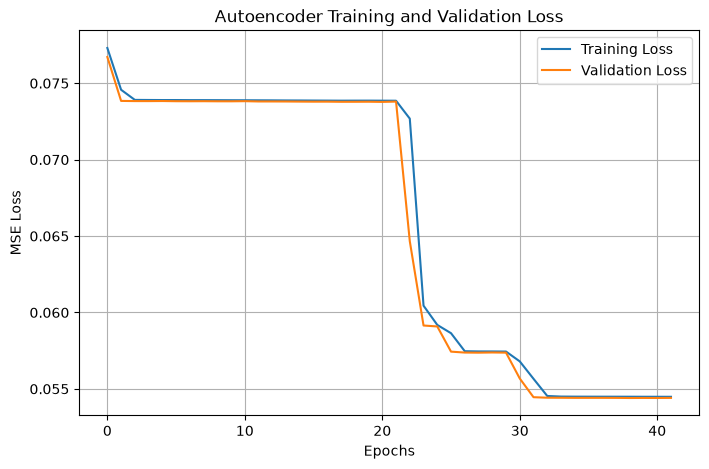

In [97]:
# training loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [110]:
train_pred = autoencoder.predict(x_train_normal)

train_error = np.mean((x_train_normal - train_pred)**2 , axis = 1)

mean = np.mean(train_error)
std = np.std(train_error)

threshold = mean + 3*std


print("Mean:", mean)
print("Standard Deviation:", std)
print("Threshold:", threshold)

73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 720us/step
Mean: 0.054465788359422375
Standard Deviation: 0.0015125379468021016
Threshold: 0.05900340219982868


In [111]:
# detect anamolies
test_pred = autoencoder.predict(x_test)
test_error = np.mean((x_test - test_pred)**2 , axis = 1)

y_pred = (test_error > threshold).astype(int)

print("Detected anomalies:", np.sum(y_pred))


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step
Detected anomalies: 48


In [112]:
# Convert predictions to match actual labels
y_pred = np.where(test_error > threshold, 0, 1)

from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[ 47 362]
 [  1 590]]
              precision    recall  f1-score   support

         0.0       0.98      0.11      0.21       409
         1.0       0.62      1.00      0.76       591

    accuracy                           0.64      1000
   macro avg       0.80      0.56      0.49      1000
weighted avg       0.77      0.64      0.54      1000



In [113]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.637
Accuracy (%): 63.7
